# Librerias

In [1]:
import sys
import os
import datetime
import time
# Agrega la carpeta raíz del proyecto al path de Python
sys.path.append(os.path.abspath(os.path.join('../')))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Activation, PReLU, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from sklearn.metrics import classification_report,confusion_matrix
from sklearn.utils.class_weight import compute_class_weight
from keras.metrics import Precision, Recall, AUC
import keras


from src.Modelo_CNN import CNN_Model_Clasification

I0000 00:00:1793572217.920678   78898 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
print(tf.config.list_physical_devices("GPU"))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# Carga de subsets

In [3]:

img_classify = CNN_Model_Clasification(32,256,256,3)
img_classify.buffer_size = 4000
img_classify.lab_mode = "int"
img_classify.categories = ['Aedes Aegypti', 'Anopheles Stephensi', 'Culex Quinquefasciatus']

In [4]:
img_classify.train_data_folder = '../data/raw/Imagenes/Mosquito Images Augmented'




In [5]:

img_classify.classify_img_by_folder()

Found 2640 files belonging to 3 classes.
Using 2112 files for training.


I0000 00:00:1793572220.652261   78898 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 4082 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1660 SUPER, pci bus id: 0000:01:00.0, compute capability: 7.5


Found 2640 files belonging to 3 classes.
Using 528 files for validation.
Train data: ['Aedes Aegypti', 'Anopheles Stephensi', 'Culex Quinquefasciatus']
Validation data: ['Aedes Aegypti', 'Anopheles Stephensi', 'Culex Quinquefasciatus']
Categorias de instancia: ['Aedes Aegypti', 'Anopheles Stephensi', 'Culex Quinquefasciatus']


In [6]:
img_classify.train_data

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 256, 256, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>

In [7]:


for lote_imagenes, lote_etiquetas in img_classify.train_data.take(1):
    
    # Convertimos los tensores a arrays de NumPy para inspeccionar sus dimensiones
    print("Forma del lote de imágenes:", lote_imagenes.numpy().shape) 
    # Resultado ej: (32, 256, 256, 3) -> (Batch, Alto, Ancho, Canales)
    
    print("Forma del lote de etiquetas:", lote_etiquetas.numpy().shape)
    # Resultado ej: (32,) -> Un número entero por cada imagen del lote
    
    # Ver los valores numéricos de las primeras 5 etiquetas del lote
    print("Primeras 5 etiquetas numéricas del lote:", lote_etiquetas.numpy()[:5])


Forma del lote de imágenes: (32, 256, 256, 3)
Forma del lote de etiquetas: (32,)
Primeras 5 etiquetas numéricas del lote: [1 2 1 1 0]


Clases detectadas: ['Aedes Aegypti', 'Anopheles Stephensi', 'Culex Quinquefasciatus']


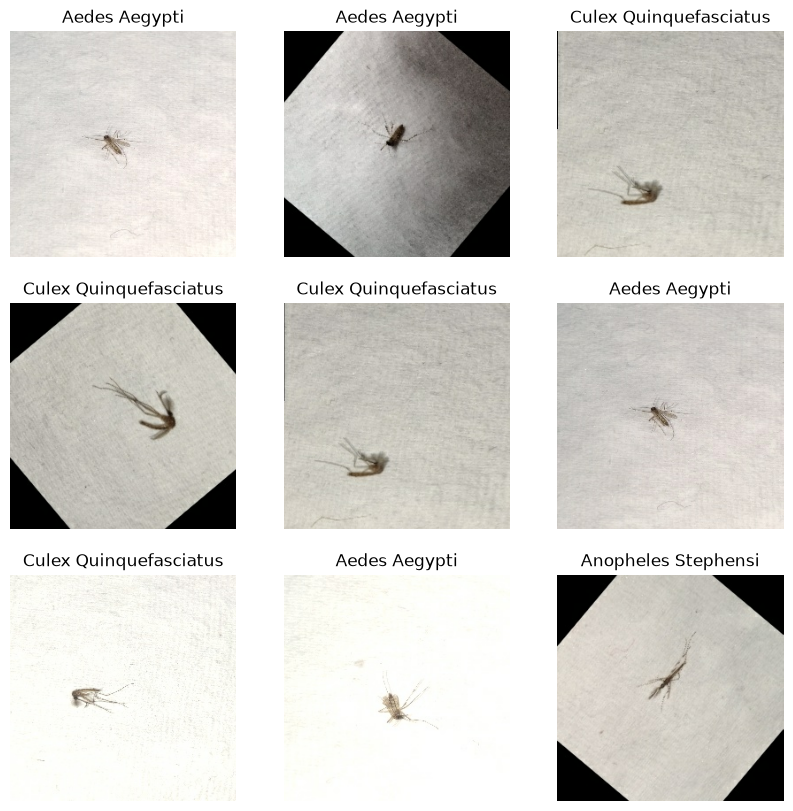

In [8]:

img_classify.show_sample_image_x_label('train')


Clases detectadas: ['Aedes Aegypti', 'Anopheles Stephensi', 'Culex Quinquefasciatus']


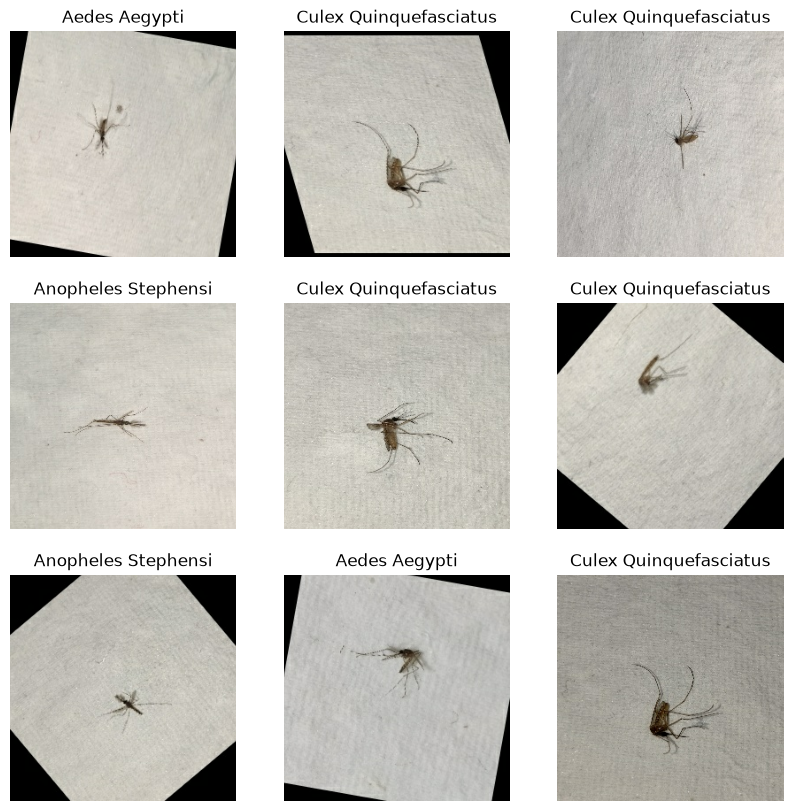

In [9]:
img_classify.show_sample_image_x_label('val')

# Configuracion de flujo y entrenamineto

In [30]:

img_classify.preparar_experimento(                                 
).model_flow_settings(
    capas_conv = 2,
    n_filtros = 32,
    n_filter_up_escale = 2,
    kernel_size = (5,5),
    pool_layer = 'max',
    pool_size = (2,2),
    transition = 'GAP',
    capas_densas = 1, 
    fun_act = 'gelu',
    loss = 'sparse_categorical_crossentropy',
    optimizer = tf.keras.optimizers.Adam(
            learning_rate=0.001,  # Tasa de aprendizaje más baja para evitar saltos caóticos
            clipvalue=1.0          # Gradient Clipping: Pone un tope de seguridad a la fuerza de actualización
        ),
    n_output = len(img_classify.categories),
    dropout = 0.4,
    fun_out= 'softmax',
    leakyrelu_negative_slope = 0.5,
    n_dense_keep = None,
    metrics = [tf.keras.metrics.SparseCategoricalAccuracy(name='accuracy')]
).model.summary()


/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA/.Vector_IA_wsl/lib/python3.12/site-packages/keras/src/layers/preprocessing/data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 256, 256, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 256, 256, 32)   │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256, 256, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256, 256, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 64)   │        51,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 58,435 (228.26 KB)

 Trainable params: 58,243 (227.51 KB)

 Non-trainable params: 192 (768.00 B)

In [31]:

img_classify.start_training(
    epochs = 600,
    callbacks = [
        
        EarlyStopping(
            monitor='val_loss', 
            mode='min',
            verbose=1, 
            patience=30,
            restore_best_weights =  True
            ),
        ModelCheckpoint(
            filepath=f"../models/CNN_Models/Img_classify/checkpoints/CNN_Vector_Clasification_3.keras",
            monitor='val_loss',
            mode='min',
            save_best_only=True
        )
        
        ]
)

🚀 Iniciando el entrenamiento...

Epoch 1/600


/home/hadoop/CUC/IA_Aplicada/Proyecto_VectorIA/.Vector_IA_wsl/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


66/66 ━━━━━━━━━━━━━━━━━━━━ 18s 244ms/step - accuracy: 0.5729 - loss: 0.9731 - val_accuracy: 0.3333 - val_loss: 1.1823
Epoch 2/600
66/66 ━━━━━━━━━━━━━━━━━━━━ 16s 239ms/step - accuracy: 0.6776 - loss: 0.7731 - val_accuracy: 0.5625 - val_loss: 1.1012
Epoch 3/600
66/66 ━━━━━━━━━━━━━━━━━━━━ 15s 227ms/step - accuracy: 0.7206 - loss: 0.6521 - val_accuracy: 0.3144 - val_loss: 1.1323
Epoch 4/600
66/66 ━━━━━━━━━━━━━━━━━━━━ 10s 145ms/step - accuracy: 0.7183 - loss: 0.6238 - val_accuracy: 0.3447 - val_loss: 1.2247
Epoch 5/600
66/66 ━━━━━━━━━━━━━━━━━━━━ 14s 208ms/step - accuracy: 0.7410 - loss: 0.5865 - val_accuracy: 0.4678 - val_loss: 1.6934
Epoch 6/600
66/66 ━━━━━━━━━━━━━━━━━━━━ 16s 240ms/step - accuracy: 0.7410 - loss: 0.5826 - val_accuracy: 0.3258 - val_loss: 1.2207
Epoch 7/600
66/66 ━━━━━━━━━━━━━━━━━━━━ 16s 245ms/step - accuracy: 0.7386 - loss: 0.5616 - val_accuracy: 0.2841 - val_loss: 3.4372
Epoch 8/600
66/66 ━━━━━━━━━━━━━━━━━━━━ 16s 245ms/step - accuracy: 0.7514 - loss: 0.5675 - val_accuracy

In [32]:
losses = pd.DataFrame(img_classify.model.history.history)


<Axes: >

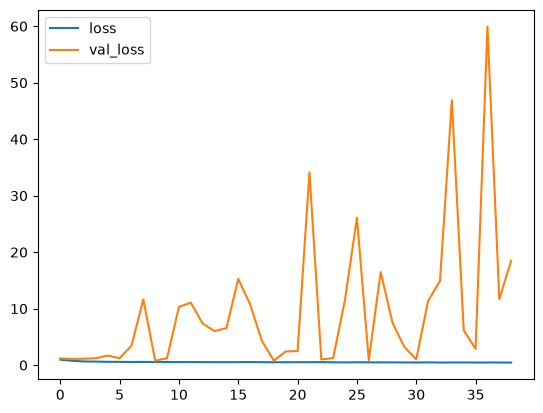

In [33]:

losses[['loss','val_loss']].plot()

<Axes: >

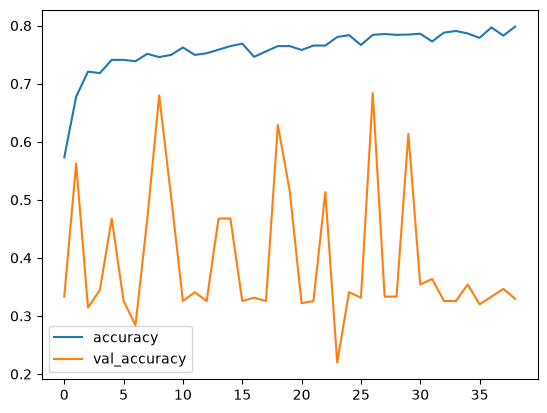

In [34]:
losses[['accuracy', 'val_accuracy']].plot()

# Evaluacion

In [35]:
#img_classify.model = tf.keras.models.load_model("../models/CNN_Models/Img_classify/checkpoints/CNN_Vector_Clasification_1.keras")

In [36]:
img_classify.img_prediction(
    '../data/raw/Imagenes/Mosquito Images Augmented/Aedes Aegypti/Aedes_aegypti_5.jpg'
)

img_classify.predictions

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step


E0000 00:00:1793575479.290053   78898 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


'Aedes Aegypti'

Conjunto: val | Ejemplos: 528
accuracy           0.6799
precision_macro    0.6227
recall_macro       0.6065
f1_macro           0.6083
f1_ponderado       0.6657
dtype: float64

Reporte por clase:
                        precision  recall  f1-score  support
Clase                                                       
Aedes Aegypti               0.578  0.5814    0.5797      172
Anopheles Stephensi         0.500  0.3394    0.4044      109
Culex Quinquefasciatus      0.790  0.8988    0.8409      247


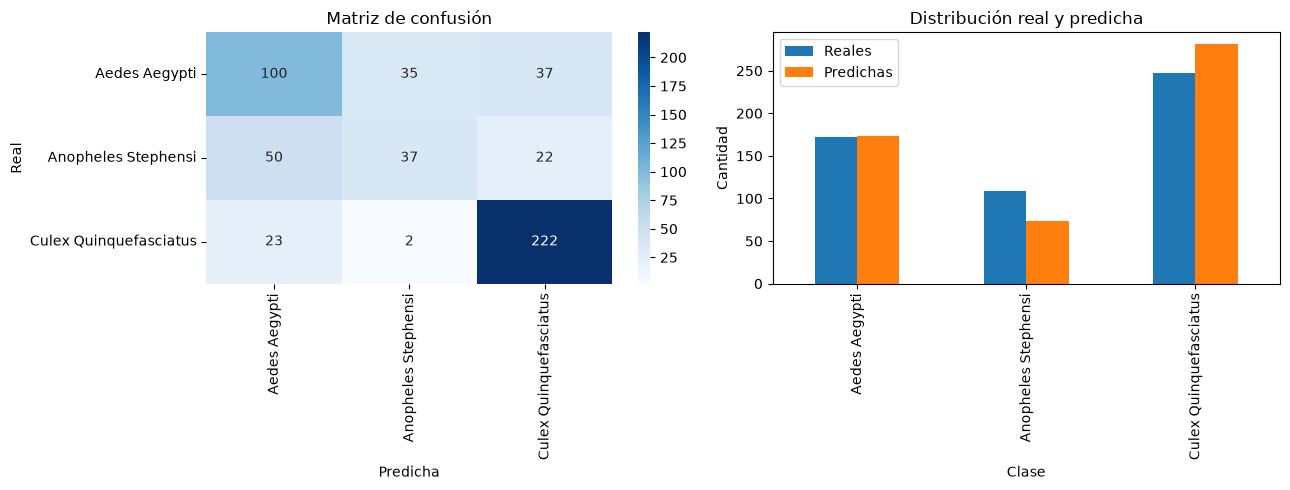

,Clase_real,Clase_predicha,Nombre_real,Nombre_predicho,Probabilidad_clase_predicha,Acierto
2,2,0,Culex Quinquefasciatus,Aedes Aegypti,0.410397,False
11,1,2,Anopheles Stephensi,Culex Quinquefasciatus,0.392809,False
12,0,1,Aedes Aegypti,Anopheles Stephensi,0.479939,False
17,2,0,Culex Quinquefasciatus,Aedes Aegypti,0.511762,False
19,1,2,Anopheles Stephensi,Culex Quinquefasciatus,0.518611,False
...,...,...,...,...,...,...
505,1,0,Anopheles Stephensi,Aedes Aegypti,0.506087,False
507,2,0,Culex Quinquefasciatus,Aedes Aegypti,0.510007,False
518,1,0,Anopheles Stephensi,Aedes Aegypti,0.390196,False
521,0,2,Aedes Aegypti,Culex Quinquefasciatus,0.900905,False


In [37]:
resultado = img_classify.evaluar(
    conjunto="val",
    tipo="multiclase",
    codificacion="indices",
    categorias= ['Aedes Aegypti', 'Anopheles Stephensi', 'Culex Quinquefasciatus']
)

resultado["reporte_por_clase"]
resultado["predicciones"].query("Acierto == False")

In [38]:
# Una vez terminado model.fit(...)
#nombre_archivo = "../models/CNN_Models/Img_classify/CNN_Vector_Clasification_3.keras"

# Guardar el modelo completo
#img_classify.model.save(nombre_archivo)
#print(f"Modelo guardado exitosamente en: {nombre_archivo}")
